# 02 - Feature engineering and modelling

Logistic regression that predicts *Likely to Change Occupation*. The code lives in the `ml/` package (also used by the API);
this notebook runs it step by step and explains the choices. Run from the `notebooks/` directory.

Three fixes compared with the first version of this notebook:

1. **Categorical encoding** - ordinal `StringIndexer` codes (Medicine = 3, Law = 7 ...) impose an order that does not exist and
   feed it to a linear model. Here every category is one-hot encoded.
2. **AUC** - the old cell evaluated `areaUnderROC` on the hard 0/1 `prediction` column. AUC needs the continuous score
   (`rawPrediction`); with hard labels it just reports a rescaled accuracy.
3. **One fitted pipeline** - indexers, encoder, assembler and classifier are one `PipelineModel`, so the API applies exactly the
   encoding learned here. (The old API refitted indexers on the request row, so every category became index 0.)

Nothing is written into the repository: `python -m ml.train` saves the model to `models/` (git-ignored).

In [1]:
import sys
sys.path.insert(0, "..")          # make the `ml` package importable from notebooks/

import json
import pandas as pd
from ml.pipeline import (build_pipeline, coefficients, evaluate, get_spark, read_raw, split)
from ml.schema import LEAKY_FEATURE

spark = get_spark("career-modelling")
spark.sparkContext.setLogLevel("ERROR")

df = read_raw(spark, "../data/raw/field_of_study_vs_occupation.csv")
train, test = split(df, seed=42)
print(f"train rows: {train.count():,}   test rows: {test.count():,}")

train rows: 30,769   test rows: 7,675


## Baseline and full model

The "majority-class baseline" is the accuracy of always answering *likely to change*; a model has to beat it.

In [2]:
full = build_pipeline().fit(train)
m_full = evaluate(full, test)
print(json.dumps(m_full, indent=2))

{
  "test_rows": 7675,
  "auc_roc": 0.9663,
  "accuracy": 0.9024,
  "f1": 0.9025,
  "majority_class_baseline": 0.5765,
  "confusion_matrix": {
    "actual_0_pred_0": 2893,
    "actual_0_pred_1": 357,
    "actual_1_pred_0": 392,
    "actual_1_pred_1": 4033
  }
}


## The leaky feature

In the raw data every person with `Career Change Interest = 1` is labelled *likely to change* (see notebook 01), and the fitted
model gives that one column a coefficient more than 20x larger than any other feature. Below are the ten largest coefficients.
(Numeric features sit on different scales, so compare coefficients only within the same kind of feature.)

In [3]:
pd.DataFrame(coefficients(full, test)[:10])

,feature,coefficient
0,career_change_interest,27.914722
1,job_satisfaction,-1.134677
2,current_occupation_ohe_Doctor,0.135846
3,field_of_study_ohe_Psychology,-0.112057
4,current_occupation_ohe_Software Developer,-0.110514
5,current_occupation_ohe_Economist,-0.102752
6,field_of_study_ohe_Medicine,0.098698
7,freelancing_experience,0.094054
8,field_of_study_ohe_Education,0.089353
9,field_of_study_ohe_Computer Science,-0.085522


## Honest model: without Career Change Interest

Whether interest in changing career should be a *predictor* of changing career is a product question; if the goal is to predict
who is at risk before they say so, the column must go. The API accepts either model (`python -m ml.train --exclude careerChangeInterest`).

In [4]:
honest = build_pipeline(exclude=[LEAKY_FEATURE]).fit(train)
m_honest = evaluate(honest, test)

summary = pd.DataFrame({"all features": m_full, "without Career Change Interest": m_honest}).drop("confusion_matrix")
summary

,all features,without Career Change Interest
test_rows,7675,7675
auc_roc,0.9663,0.8698
accuracy,0.9024,0.7749
f1,0.9025,0.7744
majority_class_baseline,0.5765,0.5765


In [5]:
pd.DataFrame({"all features": m_full["confusion_matrix"], "without Career Change Interest": m_honest["confusion_matrix"]})

,all features,without Career Change Interest
actual_0_pred_0,2893,2344
actual_0_pred_1,357,906
actual_1_pred_0,392,822
actual_1_pred_1,4033,3603


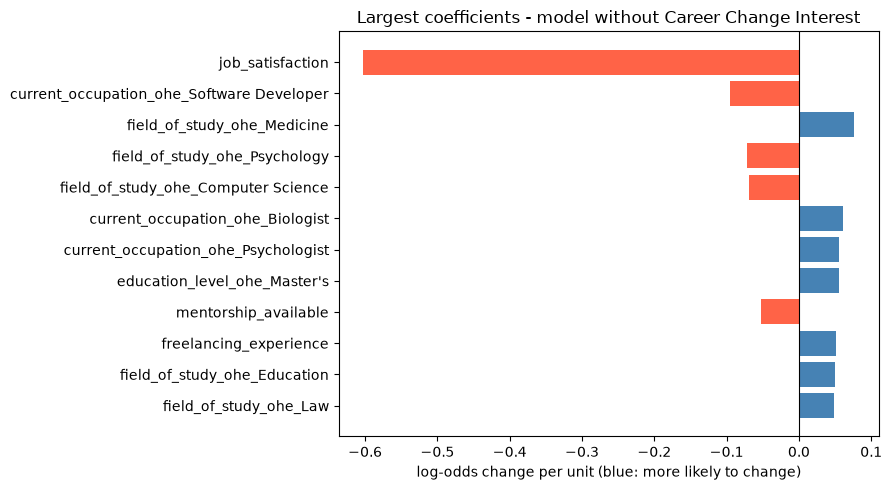

In [6]:
import matplotlib.pyplot as plt

top = pd.DataFrame(coefficients(honest, test)[:12]).iloc[::-1]
plt.figure(figsize=(9, 5))
plt.barh(top["feature"], top["coefficient"], color=["tomato" if c < 0 else "steelblue" for c in top["coefficient"]])
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Largest coefficients - model without Career Change Interest")
plt.xlabel("log-odds change per unit (blue: more likely to change)")
plt.tight_layout()
plt.show()

## Reading the result

- With every feature the model reaches 0.966 AUC and 90.2 % accuracy on 7,675 held-out rows - but most of that comes from
  `Career Change Interest`, which is effectively the label (see above).
- Without it the model reaches 0.870 AUC and 77.5 % accuracy, still 20 points above the 57.7 % majority baseline. The remaining
  signal is mostly **Job Satisfaction** (lower satisfaction, more likely to change); no field or occupation category matters much.
- The categories in this dataset are almost perfectly balanced (each field and occupation has about 3.8k rows), which suggests
  the data is synthetic. Treat the numbers as a demonstration of the pipeline, not as evidence about real careers.
- Not done here: hyper-parameter tuning, cross-validation, calibration. The split is a single 80/20 random split (seed 42).
